<div hidden>
$\DeclareMathOperator{\tr}{tr}$
$\DeclareMathOperator{\sign}{sign}$
$\DeclareMathOperator{\argmin}{argmin}$
</div>

# Trace regression

Existem problemas de regressão cujo parâmetro tem estrutura de matriz. Estimar e fazer inferência preservando a estrutura de matriz é em certos casos essencial, especialmente quando o parâmetro tem posto pequeno apesar de ser denso. Neste projeto iremos implementar métodos iterativos para achar a solução do seguinte estimador de mínimos quadrados regularizado:

$$
\min_{B\in\mathbb{R}^{d_1\times d_2}}f(B)=\frac{1}{2n}\sum_{i=1}^n(y_i-tr(X_i^\top B) ))^2 + 
\lambda\Vert B\Vert_N, 
$$
onde $(y_1,X_1), \ldots, (y_n,X_n)$ é uma amostra de labels/features em $\mathbb{R}\times\mathbb{R}^{d_1\times d_2}$. Àcima, $\lambda>0$ é um hyper-parâmetro positivo e 

$$
\Vert B\Vert_N := \sum_{j=1}^{\min\{d_1,d_2\}}\sigma(B),
$$

é a *norma nuclear* da matriz $B$, onde $\sigma_1(B)\ge\cdots\ge\sigma_{\min\{d_1,d_2\}}(B)$ são os valores singulares de $B$.  

# Soft-Thresholding matricial

Recorde que o passo de iteração do método gradiente proximal é calcular o *operador proximal* da norma $\lambda\Vert\cdot\Vert_N$:
$$
P(W,\lambda)\in\argmin_{B\in\mathbb{R}^{d_1\times d_2}}\left\{
\frac{1}{2}\Vert W - B\Vert_F^2 + \lambda\Vert B\Vert_N
\right\}.
$$


$P(W,\lambda)$ tem fórmula explicíta. Dados $\gamma\in\mathbb{R}$, defina
$$
S(\gamma,\lambda):=sign(\gamma)\cdot\max\{|\gamma|-\lambda,0\}.
$$
Àcima, $sign(\gamma)$ é o sinal de $\gamma$. Seja agora a decomposição de valores singulares (SVD) de $W$:
$$
W = U\cdot D(\gamma_1,\ldots,\gamma_r)\cdot V^\top.
$$
Então, 
$$
P(W,\lambda) = U\cdot D\left( S(\gamma_1,\lambda),\ldots, S(\gamma_r,\lambda)\right)\cdot V^\top, 
$$
chamado de matriz *soft-thresholding* de $W$ com threshold $\lambda$.

In [29]:
import matplotlib
import numpy as np
import scipy
from scipy.stats import ortho_group
import seaborn as sns
import matplotlib.pyplot as plt
import numpy.linalg as la

# Exercício 1: Gerando dados

Construa uma função ``data_genP(d1,d2,r,B_mag)`` que toma $d_1$, $d_2$, posto $r$ e número positivo ``B_mag`` e retorna a matriz $d_1\times d_2$ de posto $r$ e valores singulares todos iguais a ``B_mag``. Ao gerar esta matriz $B^*$, use a função ```scipy.stats.ortho_group``` para construir duas matrizes $U$ e $V$ aleatórias ortogonais de dimensões $d_1\times r$ e $d_2\times r$ respectivamente; retorne
$B^*=U\cdot D(B_{mag},\ldots,B_{mag})\cdot V^\top$. 

In [30]:
#Escreva código aqui
def data_genP(d1, d2, r, B_mag):
    U = ortho_group.rvs(d1)[:, :r]
    V = ortho_group.rvs(d2)[:, :r]
    diag = np.diag(np.ones(r)*B_mag)
    return U @ diag @ V.T

In [31]:
#Exemplo:
d_1=30
d_2=50
r=5
B_mag=10
B_true = data_genP(d_1,d_2,r,B_mag)
B_true.shape

(30, 50)

# Exercício:

Construa uma função ``data_genXe(n,d_1,d_2,B_true,sd)`` que toma $n$, $d_1$, $d_2$, $B_{\text{true}}$ e um número positivo ``sd`` e constrói os dados ``X``, uma lista de $n$ matrizes $X_i$ de dimensão $d_1\times d_2$ independentes cujas entradas são iid normais padrão. A função também retorna o vetor ``y`` de dimensão $n$ cujas coordenadas satisfazem

$$
y_i = tr(X_i^\top B_{\text{true}}) + \text{sd}\cdot\epsilon_i,
$$
onde $\{\epsilon_i\}_{i=1}^n$ é uma sequência iid de normais padrão. 

In [32]:
#Escreva código aqui
def data_genXe(n, d1, d2, B_true, sd):
    Xs = [np.random.normal(0, 1, (d1, d2)) for _ in range(n)]
    eps = np.random.normal(0, 1, n)
    ys = np.array([np.linalg.trace(Xs[i].T @ B_true) + sd * eps[i] for i in range(n)])
    return Xs, ys

In [33]:
#Exemplo:
sd = 2
n = 100

B_true = data_genP(d_1,d_2,r,B_mag)
X,y = data_genXe(n,d_1,d_2,B_true,sd)

In [34]:
type(X), len(X), X[0].shape

(list, 100, (30, 50))

In [35]:
type(y), len(y), y.shape

(numpy.ndarray, 100, (100,))

# Exercício:

Construa uma função ``soft(x,l)`` que retorna $S(x,\lambda)$.

In [36]:
#Escreva código aqui
def soft(x,l):
    return np.sign(x)*np.max([np.abs(x)-l,0])

# Exercício 2: 

Vamos usar o método gradiente proximal para resolver o problema àcima:

\begin{align*}
W_{k+1} &:= B_k - \frac{1}{L}\nabla f(B_k),\\
B_{k+1} &:= P\left(W_{k+1},\frac{\lambda}{L}\right).
\end{align*}

Construa uma função ``trace_reg(n,d_1,d_2,X,y,L,lambd,B0,t_final)`` onde, $1/L$ é o passo, ``lambd`` ($=\lambda$) é o fator de penalização, ``B0`` é o ponto inicial, a variável ``t_final`` é o número de iterações. A função deve retornar a sequência $k\mapsto\frac{1}{2n}\sum_{i=1}^n(y_i-tr(X_i^\top B_k))^2$ e o último iterado $B_{t\_final}$. Use penalização

$$
\lambda = \text{sd}\sqrt{\frac{d_1+d_2}{n}}, 
$$

e passo $A/L$ ajustando $A\ge1$ com

$$
L = A \cdot \lambda_{\max}\left(
\frac{1}{n}\sum_{i=1}^n\text{vec}(X_i)\text{vec}^\top(X_i)
\right),
$$ 
onde $\text{vec}(X_i)$ representa a matrix $d_1\times d_2$ $X_i$ em forma vetorial de dimensão $d_1d_2$. 

**TEM QUE ENTENDER COMO CALCULAR O GRADIENTE}!**

Calculando o gradiente:

$$
f(B) = \frac{1}{2n}\sum_{i=1}^n(y_i-tr(X_i^\top B) ))^2 + \lambda\Vert B\Vert_N
\\
\nabla f(B) = \frac{1}{n}\sum_{i=1}^{n}(tr(X_i^\top B) - y_i)X_i + \lambda U V^\top
\\
\text{onde: } B = U\Sigma V^\top 
$$

In [37]:
#Escreva código aqui
import copy

def func_e_grad(X, y, B, lambd):
    tr = np.einsum('ijk,jk->i', X, B)
    U, S, Vt = np.linalg.svd(B, full_matrices=False)

    f_loss = 1/(2*y.shape[0])*np.sum((y-tr)**2)
    f_reg = lambd * np.sum(S)

    g_loss = 1/(y.shape[0])*np.einsum('i,ijk->jk', tr-y, X)
    g_reg = lambd * U@Vt

    return f_loss, f_reg, g_loss, g_reg

def calc_P(W, lambd):
    U, S, Vt = np.linalg.svd(W, full_matrices=False)
    return U @ np.diag(np.array([soft(gamma, lambd) for gamma in S])) @ Vt

def trace_reg(n, d1, d2, X, y, L, lambd, B0, t_final):
    Xs = np.array(X)
    ys = y.copy()

    Bk = copy.deepcopy(B0)
    fl, _, gl, gr = func_e_grad(Xs, ys, Bk, lambd)
    Wk = Bk - (1/L)*(gl+gr)

    losses = np.empty(t_final+1)
    losses[0] = fl
    for i in range(t_final):
        Bk = calc_P(Wk, lambd/L)
        fl, _, gl, gr = func_e_grad(Xs, ys, Bk, lambd)
        Wk = Bk - (1/L)*(gl+gr)

        losses[i+1] = fl

    return losses, Bk

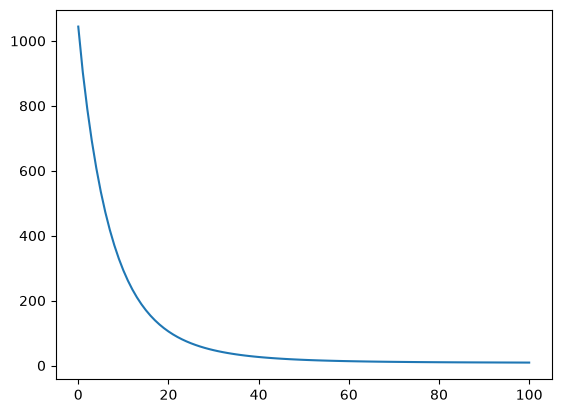

In [38]:
#Exemplo:
B0 = np.ones((d_1,d_2))
t_final = 100

#Cálculo de L:
aux = []
for i in range(n):
    xi = np.asarray(X[i])
    aux.append(xi @ xi.T)
L = 4*np.max(la.eigvalsh(sum(aux)/n))


lambd = sd*np.sqrt((d_1+d_2)/n)      

f1 = trace_reg(n,d_1,d_2,X,y,L,lambd,B0,t_final)
plt.plot(f1[0])

# Exercício: 

O que acontece se $A$ for muito pequeno? 

# Exercício 3: 

Agora, vamos usar o método gradiente proximal acelerado: iniciando de `B0=Z0` e $t_0=1$:

\begin{align*}
Z_{k+1}&:= P\left(
B_k - (1/L)\nabla f(B_k), \frac{\lambda}{L}
\right),\\
t_{k+1} &:= \frac{1+\sqrt{1+4t_k^2}}{2},\\
B_{k+1} &:= Z_{k+1} + \frac{t_{k}-1}{t_{k+1}}(Z_{k+1} - Z_{k}).
\end{align*}

Construa uma função ``trace_reg_acc(n,d_1,d_2,X,y,L,lambd,B0,t_final)`` onde, $1/L$ é o passo, ``lambd`` ($=\lambda$) é o fator de penalização, ``B0`` é o ponto inicial, a variável ``t_final`` é o número de iterações. A função deve retornar a sequência $k\mapsto\frac{1}{2n}\sum_{i=1}^n(y_i-tr(X_i^\top B_k))^2$ e o último iterado $B_{t_final}$. Use penalização

$$
\lambda = \text{sd}\sqrt{\frac{d_1+d_2}{n}}, 
$$

e passo $A/L$ ajustando $A\ge1$ com

$$
L = ??,
$$ 

In [40]:
#Escreva código aqui
def trace_reg_acc(n, d1, d2, X, y, L, lambd, B0, t_final):
    Xs = np.array(X)
    ys = y.copy()    

    Bk = copy.deepcopy(B0)
    Zk = copy.deepcopy(B0)
    tk = 0

    fl, _, gl, gr = func_e_grad(Xs, ys, Bk, lambd)
    Zk1 = calc_P(Bk - (1/L)*(gl+gr), lambd/L)
    tk1 = (1 + (1+4*tk**2)**(1/2))/2

    losses = np.empty(t_final+1)
    losses[0] = fl
    for i in range(t_final):
        Bk = Zk1 + (tk-1)*(Zk1-Zk)/tk1
        fl, _, gl, gr = func_e_grad(Xs, ys, Bk, lambd)
        losses[i+1] = fl

        Zk = Zk1
        tk = tk1
        Zk1 = calc_P(Bk - (1/L)*(gl+gr), lambd/L)
        tk1 = (1 + (1+4*tk**2)**(1/2))/2

    return losses, Bk

    

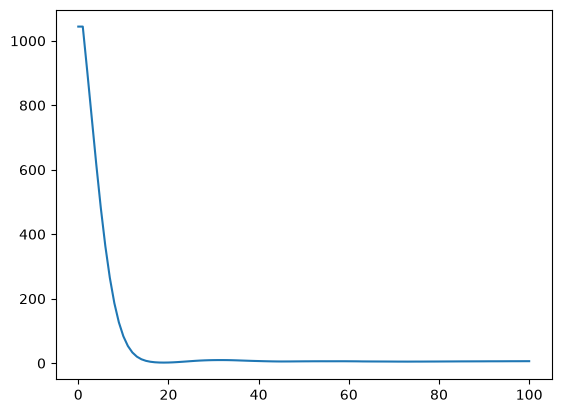

In [41]:
B0 = np.ones((d_1,d_2))
t_final = 100
lambd = sd*np.sqrt((d_1+d_2)/n)      

f2 = trace_reg_acc(n,d_1,d_2,X,y,L,lambd,B0,t_final)
plt.plot(f2[0])

# Exercício 4: 

Implemente num mesmo gráfico os erros $k\mapsto\frac{1}{2n}\sum_{i=1}^n(y_i-tr(X_i^\top B_k))^2$ de cada método em função no número de iterações.

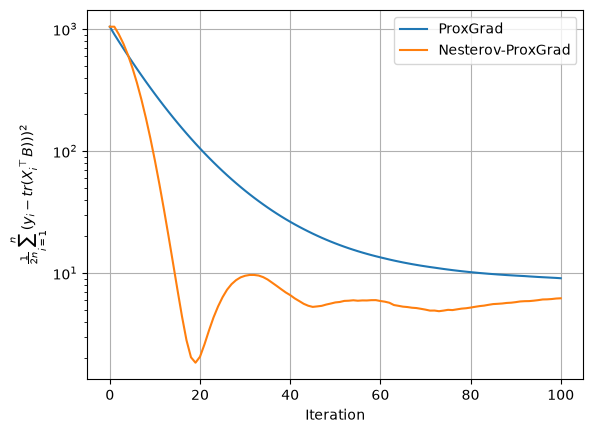

In [43]:
#Escreva código aqui
plt.plot(f1[0], label='ProxGrad')
plt.plot(f2[0], label='Nesterov-ProxGrad')

plt.xlabel('Iteration')
plt.ylabel(r'$\frac{1}{2n}\sum_{i=1}^n(y_i-tr(X_i^\top B) ))^2$')
plt.yscale('log')
plt.legend()
plt.grid(True)

# Exercício:

Refaça os exercícios com $\sigma=1$ e $\sigma=10$. Qual a diferença quando $\sigma=10$? Tem alguma intuição de porque isso acontece?

In [45]:
#Exemplo:
X_sd1,y_sd1 = data_genXe(n,d_1,d_2,B_true,1)
X_sd10,y_sd10 = data_genXe(n,d_1,d_2,B_true,10)

In [46]:
f1_sd1 = trace_reg(n,d_1,d_2,X_sd1,y_sd1,L,lambd,B0,t_final)
f1_sd10 = trace_reg(n,d_1,d_2,X_sd10,y_sd10,L,lambd,B0,t_final)

Text(0.5, 1.0, 'ProxGrad')

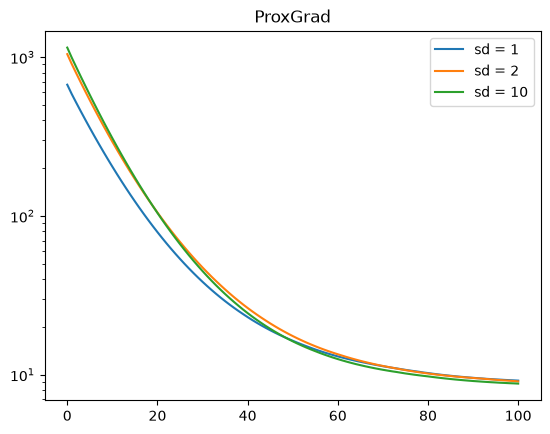

In [50]:
plt.plot(f1_sd1[0], label='sd = 1')
plt.plot(f1[0], label='sd = 2')
plt.plot(f1_sd10[0], label='sd = 10')
plt.yscale('log')
plt.legend()
plt.title('ProxGrad')

In [48]:
f2_sd1 = trace_reg_acc(n,d_1,d_2,X_sd1,y_sd1,L,lambd,B0,t_final)
f2_sd10 = trace_reg_acc(n,d_1,d_2,X_sd10,y_sd10,L,lambd,B0,t_final)

Text(0.5, 1.0, 'Nesterov-ProxGrad')

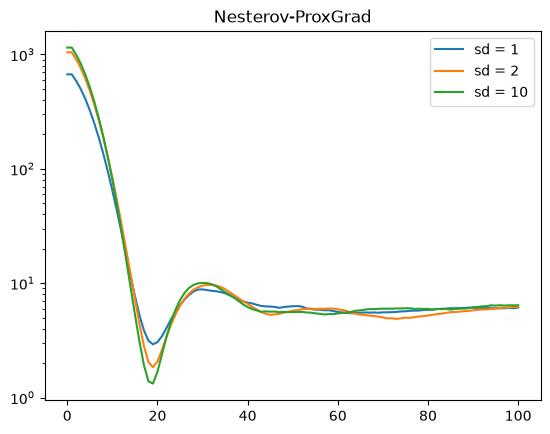

In [51]:
plt.plot(f2_sd1[0], label='sd = 1')
plt.plot(f2[0], label='sd = 2')
plt.plot(f2_sd10[0], label='sd = 10')
plt.yscale('log')
plt.legend()
plt.title('Nesterov-ProxGrad')